# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def read_points(path):
    data = pd.read_excel(path, header=None)
    data = data.iloc[:, :2]
    if (data.iloc[0, 0] == "X"):
        data = data.iloc[1:]
    data = data.astype(float)
    x = data.iloc[:, 0].values
    y = data.iloc[:, 1].values
    return x, y


def plot_points(x, y, labels=None, centers=None, title=""):
    plt.figure(figsize=(9, 9))
    if labels is None:
        plt.scatter(x, y, s=5)
    else:
        plt.scatter(x, y, c=labels, s=5)
    if centers is not None:
        for cx, cy in centers:
            plt.scatter(cx, cy, c="red", marker="x", s=150)
    plt.grid(True)
    plt.show()

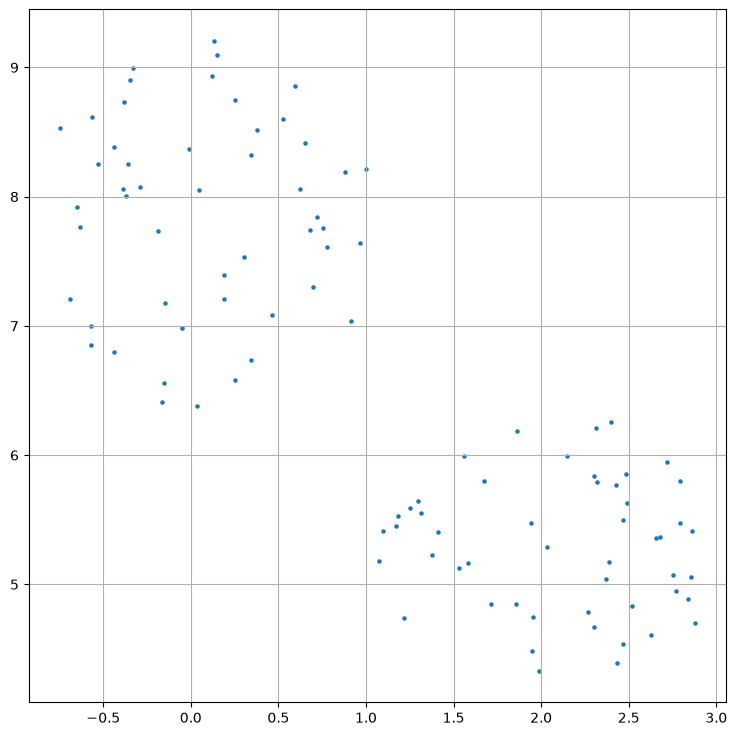

In [101]:
x, y = read_points("0.xls")
plot_points(x, y)

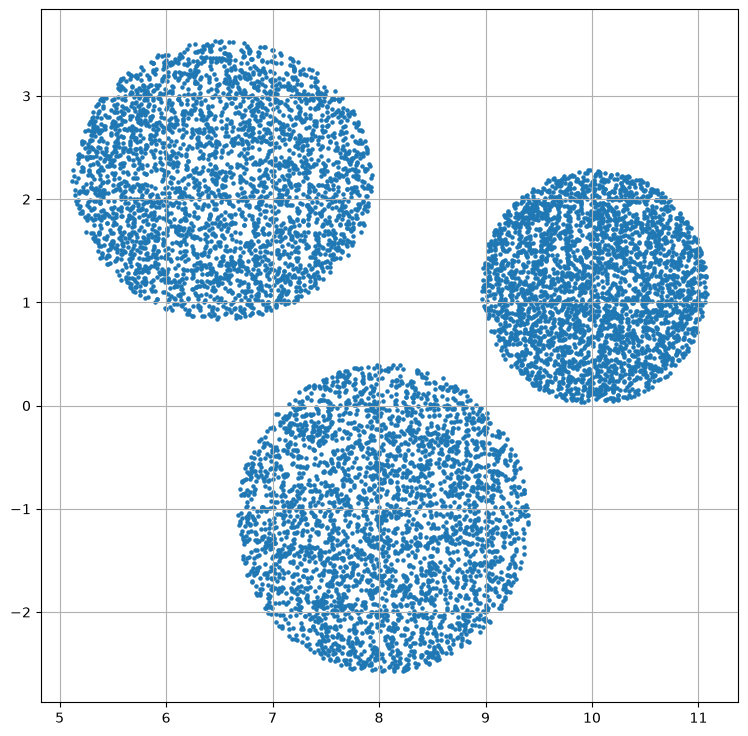

In [102]:
x, y = read_points("1.xls")
plot_points(x, y)

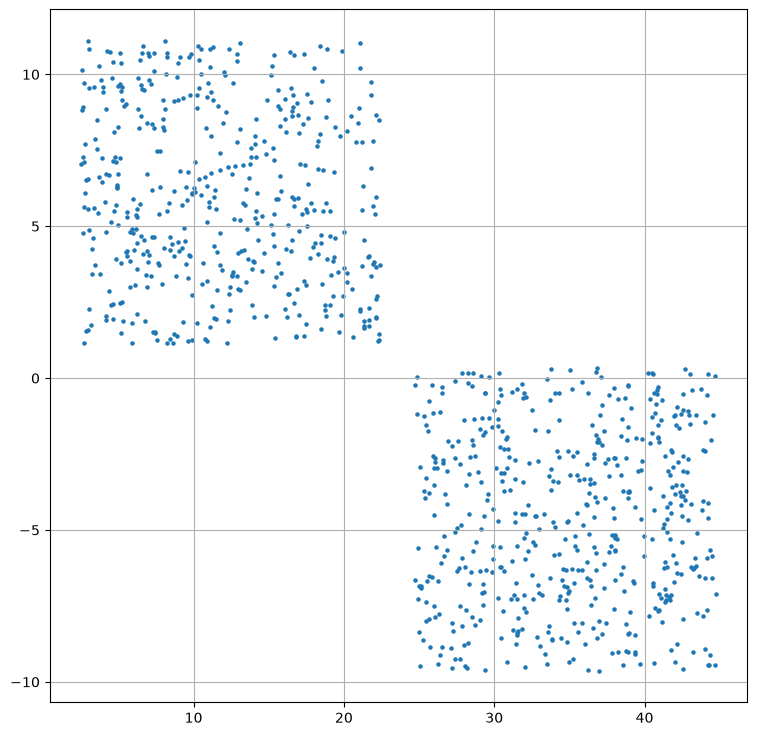

In [103]:
x, y = read_points("2.xlsx")
plot_points(x, y)

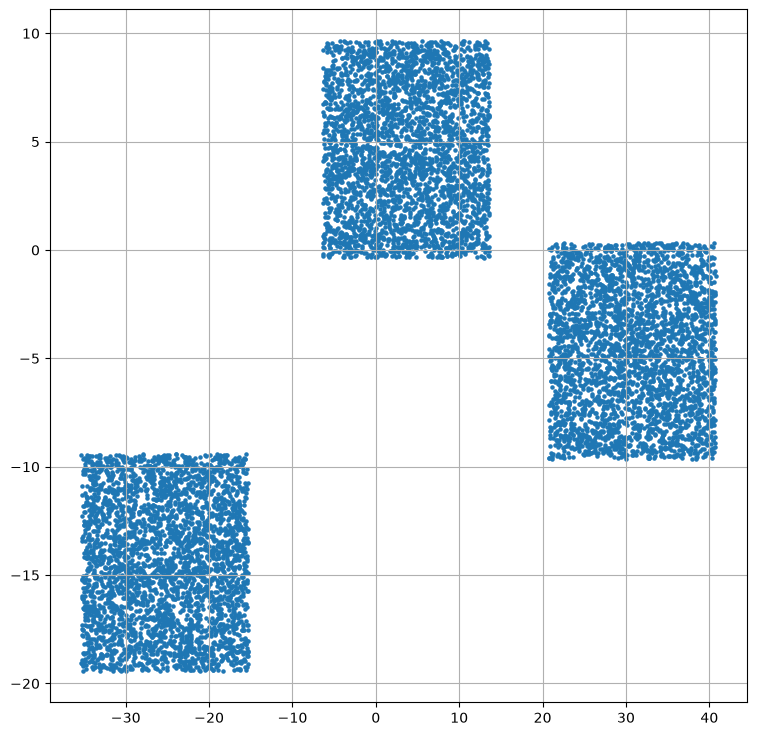

In [104]:
x, y = read_points("3.xlsx")
plot_points(x, y)

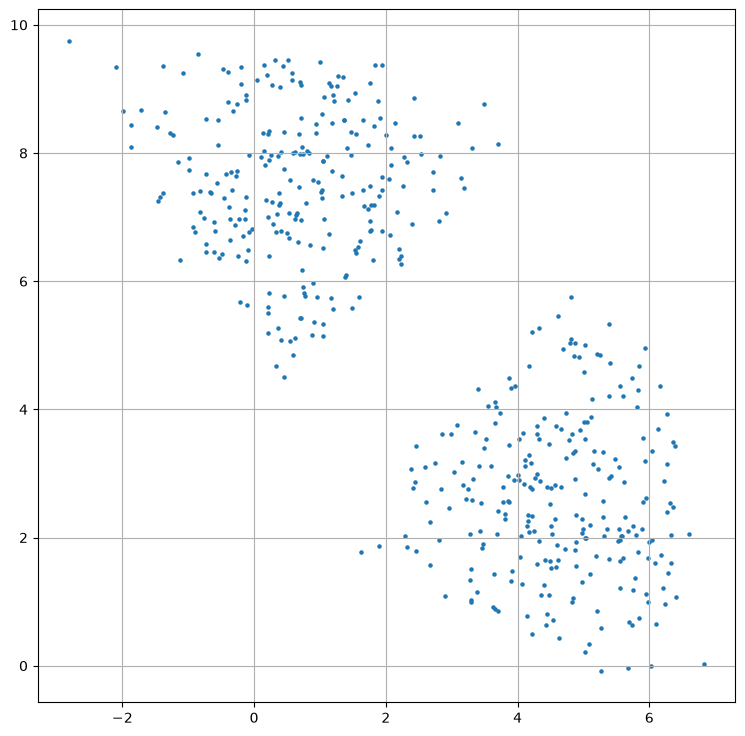

In [105]:
x, y = read_points("4.xlsx")
plot_points(x, y)

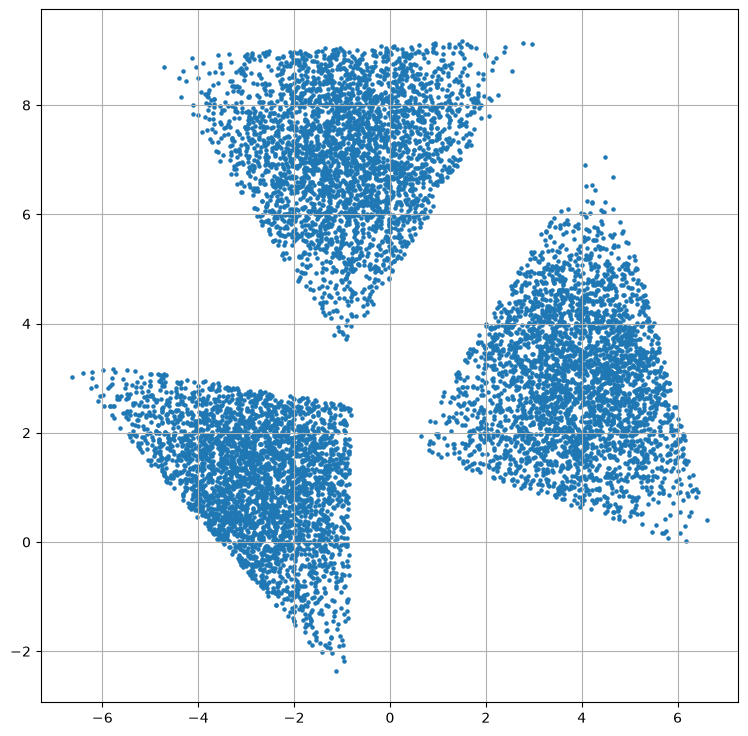

In [106]:
x, y = read_points("5.xlsx")
plot_points(x, y)

In [107]:
def clusters_0(x, y):
    labels = np.zeros(len(x), dtype=int)
    for i in range(len(x)):
        if y[i] > x[i] + 5:
            labels[i] = 0
        else:
            labels[i] = 1
    return labels

def clusters_1(x, y):
    labels = np.full(len(x), -1)
    for i in range(len(x)):
        if (x[i] - 6.5) ** 2 + (y[i] - 2.2) ** 2 <= 1.5 ** 2:
            labels[i] = 0
        elif (x[i] - 10) ** 2 + (y[i] - 1.1) ** 2 <= 1.3 ** 2:
            labels[i] = 1
        else:
            labels[i] = 2
    return labels


def clusters_2(x, y):
    labels = np.zeros(len(x), dtype=int)
    for i in range(len(x)):
        if y[i] < 1:
            labels[i] = 1
    return labels


def clusters_3(x, y):
    labels = np.zeros(len(x), dtype=int)
    for i in range(len(x)):
        if x[i] < -12:
            labels[i] = 0
        elif x[i] > 18:
            labels[i] = 2
        else:
            labels[i] = 1
    return labels


def clusters_4(x, y):
    labels = np.zeros(len(x), dtype=int)
    for i in range(len(x)):
        if y[i] > x[i] + 2:
            labels[i] = 0
        else:
            labels[i] = 1
    return labels


def clusters_5(x, y):
    labels = np.zeros(len(x), dtype=int)
    for i in range(len(x)):
        if x[i] < 0 and y[i] < 3.7:
            labels[i] = 0
        elif y[i] > x[i] + 3.6:
            labels[i] = 1
        else:
            labels[i] = 2
    return labels

In [108]:
def find_center(xs, ys, metric):
    best_sum = None
    best_i = 0
    for i in range(len(xs)):
        total = 0
        for j in range(len(xs)):
            dx = abs(xs[i] - xs[j])
            dy = abs(ys[i] - ys[j])
            if metric == "manhattan":
                total += dx + dy
            else:
                total += (dx ** 2 + dy ** 2) ** 0.5
        if best_sum is None or total < best_sum:
            best_sum = total
            best_i = i
    return xs[best_i], ys[best_i]

In [109]:
def process(x, y, clusters_function, metric="euclid"):
    labels = clusters_function(x, y)

    centers = []
    for k in sorted(set(labels)):
        xs = x[labels == k]
        ys = y[labels == k]
        cx, cy = find_center(xs, ys, metric)
        centers.append((cx, cy))

    sum_x = 0
    sum_y = 0
    for center in centers:
        sum_x += center[0]
        sum_y += center[1]
    px = sum_x / len(centers) * 1000
    py = sum_y / len(centers) * 1000
    print("Ответ:", int(px), int(py))

    plot_points(x, y, labels, centers)

Ответ: 1041 6671


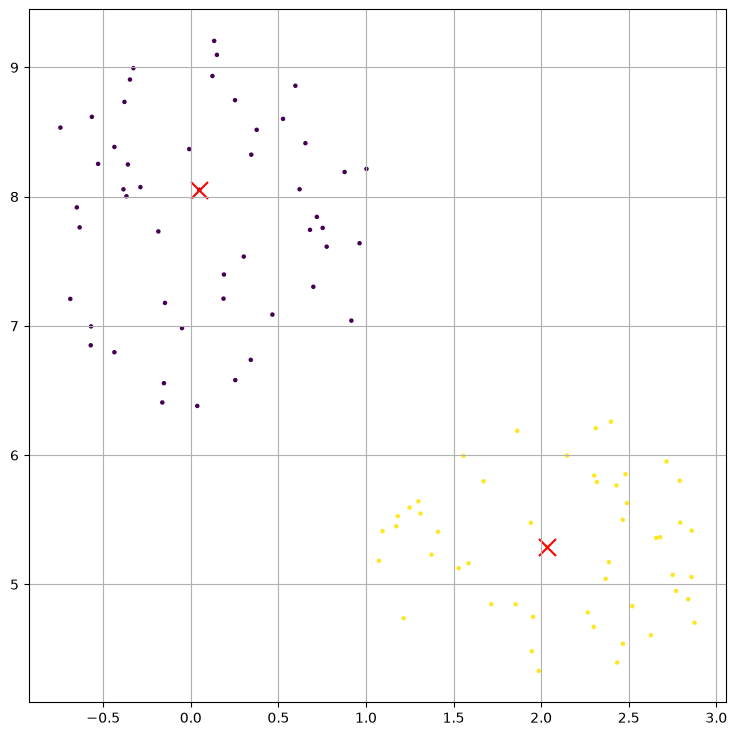

In [110]:
x, y = read_points("0.xls")
process(x, y, clusters_0)

Ответ: 8177 738


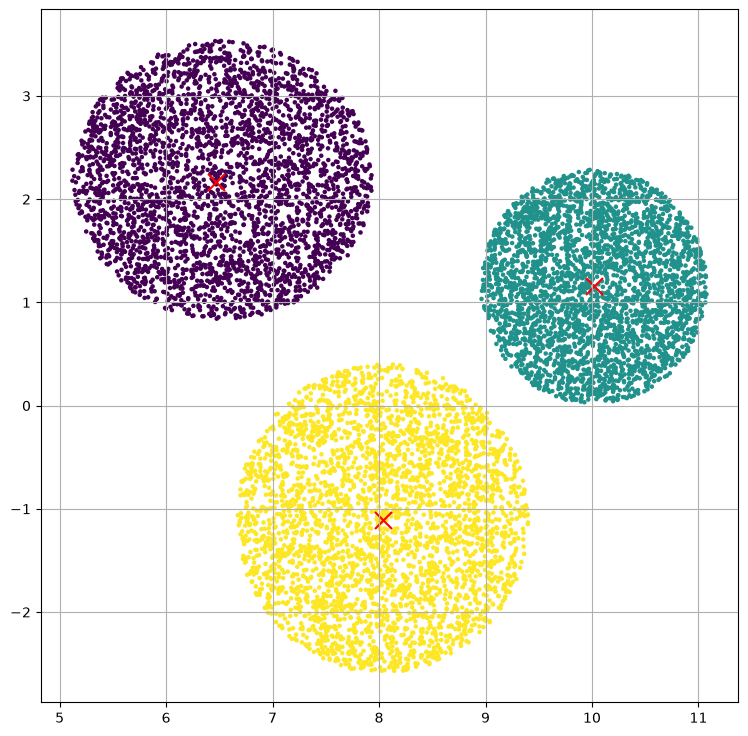

In [111]:
x, y = read_points("1.xls")
process(x, y, clusters_1)

Ответ: 23130 635


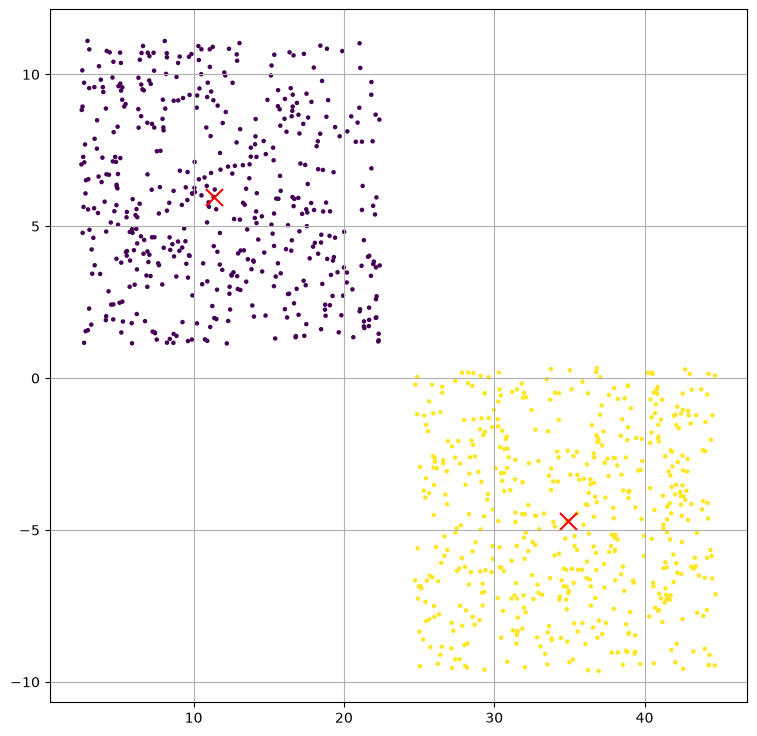

In [112]:
x, y = read_points("2.xlsx")
process(x, y, clusters_2)

Ответ: 3078 -4758


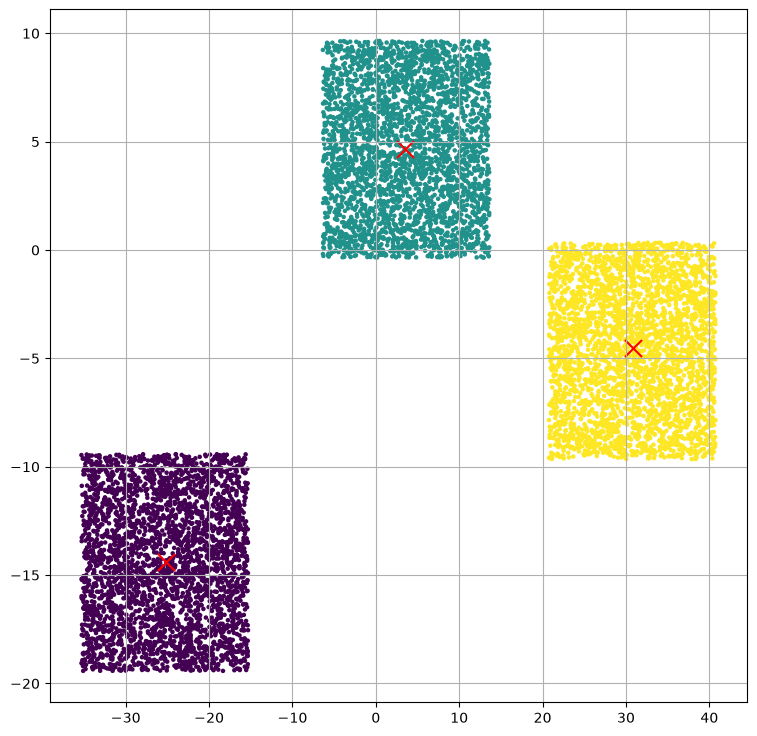

In [113]:
x, y = read_points("3.xlsx")
process(x, y, clusters_3, "manhattan")

Ответ: 2588 4996


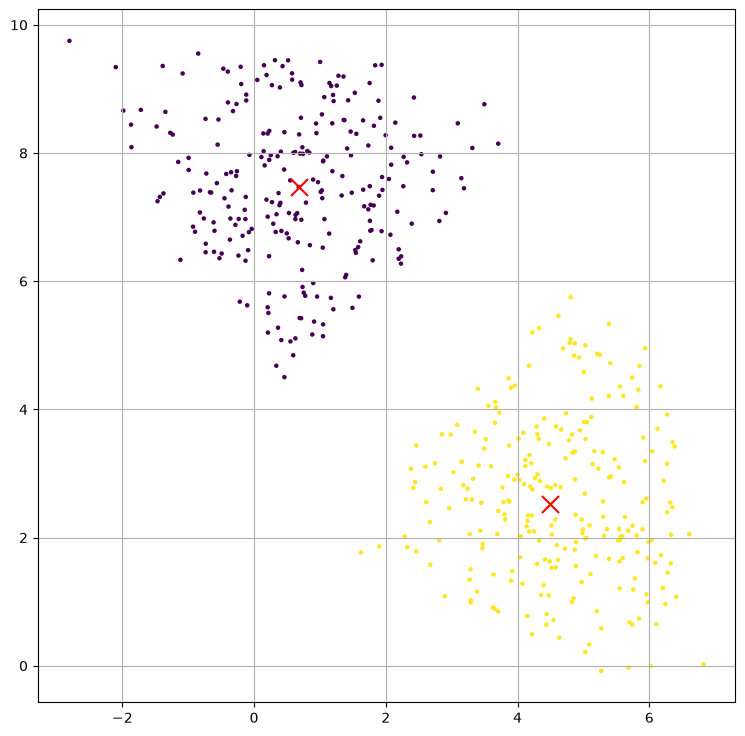

In [114]:
x, y = read_points("4.xlsx")
process(x, y, clusters_4, "manhattan")

Ответ: 61 3723


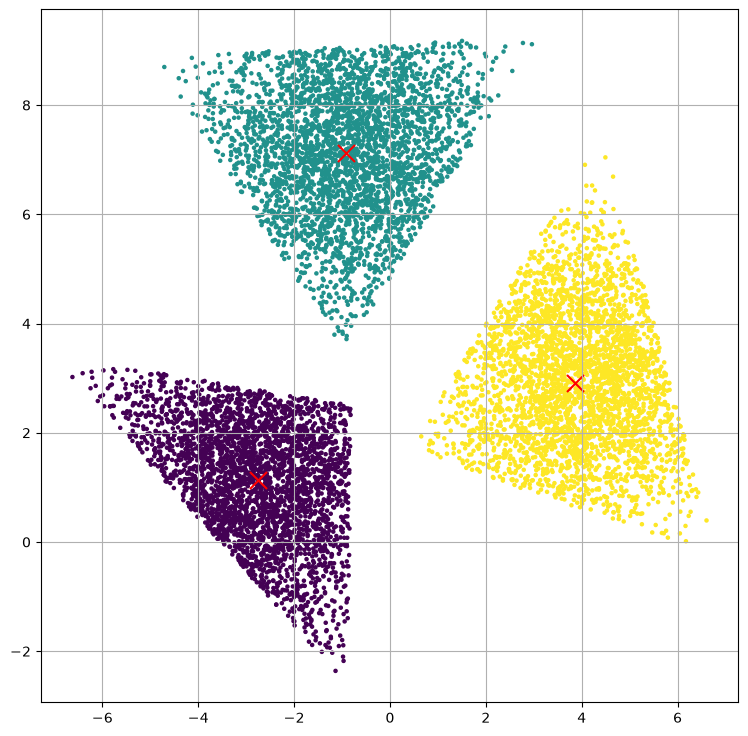

In [115]:
x, y = read_points("5.xlsx")
process(x, y, clusters_5)

# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [ ]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [ ]:
two_means =  
dbscan = 

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

In [ ]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    for name, algorithm in clustering_algorithms:
        t0 = time.time()